In [1]:
import os

YUNET_MODEL_PATH = "/kaggle/working/face_detection_yunet_2023mar_secound.onnx"

if not os.path.isfile(YUNET_MODEL_PATH):
    !wget -q -O {YUNET_MODEL_PATH} https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx

print("Model exists:", os.path.isfile(YUNET_MODEL_PATH), "-", os.path.getsize(YUNET_MODEL_PATH), "bytes")

Model exists: True - 232589 bytes


In [2]:
import os, cv2, numpy as np, keras
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# ---------- paths (edit these) ----------
MODEL_PATH   = "/kaggle/input/models/winminoolol/xception-model/keras/default/1/xception_model.keras"
YUNET_PATH   = "/kaggle/working/face_detection_yunet_2023mar_secound.onnx"
GALLERY_DIR  = "/kaggle/input/datasets/winminoolol/picture/pic/gallery"
TEST_IMAGE   = "/kaggle/input/datasets/winminoolol/picture/pic/test_img.jpg"
IMG_SIZE     = 299

# ---------- 1. Load model and cut at the GAP layer ----------
loaded_model = keras.models.load_model(MODEL_PATH)
gap_name = [l.name for l in loaded_model.layers
            if isinstance(l, keras.layers.GlobalAveragePooling2D)][0]
print("Feature layer:", gap_name)

intermediate_layer_model = keras.Model(
    inputs=loaded_model.input,
    outputs=loaded_model.get_layer(gap_name).output)      # output: 2048-d vector

I0000 00:00:1790846896.188388      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790846896.191501      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Feature layer: global_average_pooling2d


In [4]:
# ---------- 2. Face detector (YuNet) ----------
face_detector = cv2.FaceDetectorYN.create(YUNET_PATH, "", (320, 320), score_threshold=0.7)

def crop_face(img_bgr):
    """Detect the first face and crop it. Falls back to the full image."""
    h, w = img_bgr.shape[:2]
    face_detector.setInputSize((w, h))
    _, faces = face_detector.detect(img_bgr)
    if faces is None:
        print("  no face detected -> using full image")
        return img_bgr
    x, y, fw, fh = faces[0][:4].astype(int)
    x, y = max(0, x), max(0, y)
    return img_bgr[y:y + fh, x:x + fw]

In [5]:
# ---------- 3. Image -> feature vector ----------
def extract_feature(path):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(path)
    face = crop_face(img_bgr)
    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)          # model was trained on RGB
    face = cv2.resize(face, (IMG_SIZE, IMG_SIZE))
    batch = np.expand_dims(face.astype("float32"), axis=0)  # raw 0-255; Rescaling is in the model
    feat = intermediate_layer_model.predict(batch, verbose=0)
    return feat.flatten(), face

In [6]:
# ---------- 4. Build the gallery ----------
features, labels, faces_shown = [], [], []
for name in sorted(os.listdir(GALLERY_DIR)):
    print("Gallery:", name)
    f, face = extract_feature(os.path.join(GALLERY_DIR, name))
    features.append(f)
    labels.append(os.path.splitext(name)[0])
    faces_shown.append(face)
features = np.array(features)
print("Gallery feature matrix:", features.shape) 

Gallery: 01.jpg


2026-10-01 09:29:31.718676: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 09:29:31.862692: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 09:29:32.669493: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 09:29:32.802581: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 09:29:33.636176: E external/local_xla/xla/stream_

Gallery: 02.jpg
Gallery: 03).jpg
Gallery: 04.jpg
Gallery: 05.jpg
Gallery feature matrix: (5, 2048)


In [7]:
# ---------- 5. 1:N check with the test image ----------
feat_test, face_test = extract_feature(TEST_IMAGE)
sim = cosine_similarity([feat_test], features)[0]

for lab, s in sorted(zip(labels, sim), key=lambda t: -t[1]):
    print(f"{lab:12s} {s:.4f}")

order = np.argsort(sim)[::-1]
best, second = order[0], order[1]
print(f"\nBest match : {labels[best]}  (similarity {sim[best]:.4f})")
print(f"Margin over 2nd best: {sim[best] - sim[second]:.4f}")

THRESHOLD = 0.70                                          # tune this on your own data
print("Result:", labels[best] if sim[best] >= THRESHOLD else "UNKNOWN (below threshold)")

05           0.7695
01           0.5778
03)          0.5666
02           0.4168
04           0.3633

Best match : 05  (similarity 0.7695)
Margin over 2nd best: 0.1917
Result: 05


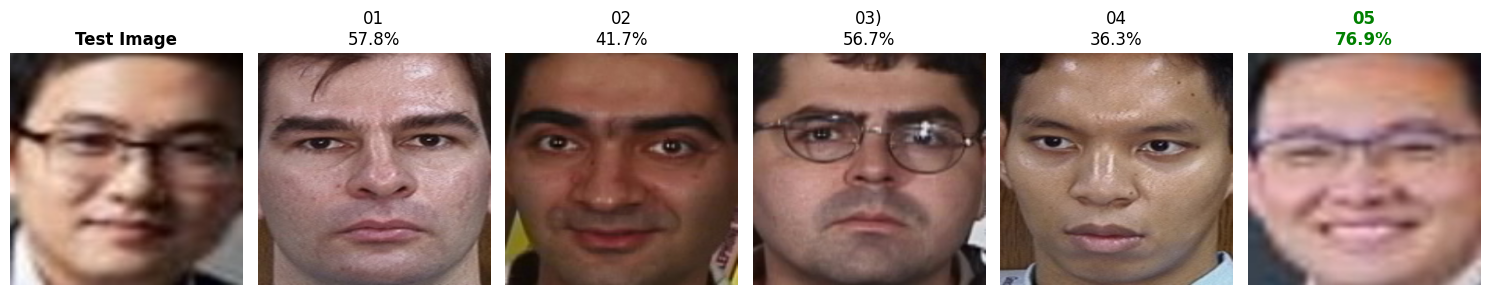

In [9]:
# ---------- 6. Show the result ----------
n_gallery = len(faces_shown)

# Create subplots: 1 for Test Image + 1 for each Gallery Image
fig, axes = plt.subplots(1, n_gallery + 1, figsize=(2.5 * (n_gallery + 1), 3.5))

# 1. Show the Test Image
axes[0].imshow(face_test)
axes[0].set_title("Test Image", fontweight="bold")
axes[0].axis("off")

# 2. Show all Gallery Images
for i in range(n_gallery):
    ax = axes[i + 1]
    ax.imshow(faces_shown[i])
    
    # Format similarity as a percentage
    sim_pct = sim[i] * 100
    title_text = f"{labels[i]}\n{sim_pct:.1f}%"
    
    # Highlight the best match with green and bold text
    if i == best:
        ax.set_title(title_text, color="green", fontweight="bold")
    else:
        ax.set_title(title_text)
        
    ax.axis("off")

plt.tight_layout()
plt.show()

# optional: save the gallery so you don't recompute it
np.save("gallery_features.npy", features)